# 화학공정 시계열 데이터 EDA

이 노트북은 결함 유형 예측이나 결함 시점 탐지 모델을 만들기 **전**에 데이터가 어떤 구조와 품질을 갖는지 확인하기 위한 탐색적 분석입니다.

이번 EDA의 질문은 다음과 같습니다.

1. 실제 데이터의 기간, 주기, 반응기 구성은 문서 설명과 일치하는가?
2. 중복, 시간 누락, 결측치는 어느 정도인가?
3. 운전 조건과 결함 유형은 얼마나 불균형한가?
4. 주요 센서와 전력 소비량의 분포 및 시간 변화는 어떠한가?
5. 결함 상태에서 정상 상태와 다른 기초 패턴이 보이는가?

> 주의: 이 데이터는 규칙 기반 합성 데이터입니다. 아래 관계는 인과관계가 아니라 모델링 가설을 만들기 위한 관찰입니다.


## 0. 분석 환경과 데이터 로드

777,600행 전체를 통계 계산에 사용합니다. 산점도처럼 점이 겹치기 쉬운 그림만 재현 가능한 무작위 표본을 사용합니다.


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.figsize": (12, 5),
    "axes.titlesize": 13,
    "axes.labelsize": 10,
    "font.size": 10,
    "font.family": "Nanum Gothic",
    "axes.unicode_minus": False,
})

DATA_PATH = Path("data/chemical_process_timeseries.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("../data/chemical_process_timeseries.csv")

df = pd.read_csv(DATA_PATH, parse_dates=["timestamp"])
df = df.sort_values(["reactor_id", "timestamp"]).reset_index(drop=True)

print(f"데이터 경로: {DATA_PATH.resolve()}")
print(f"크기: {df.shape[0]:,}행 × {df.shape[1]}열")
print(f"메모리 사용량: {df.memory_usage(deep=True).sum() / 1024**2:,.1f} MB")
print(df.head(3).to_string(index=False))


데이터 경로: /Users/hyemi/green-pulse-ai/data/chemical_process_timeseries.csv
크기: 777,600행 × 21열
메모리 사용량: 201.0 MB
          timestamp operating_regime reactor_id  ambient_temp_effect  reactor_temp  reactor_pressure  feed_flow_rate  coolant_flow_rate  agitator_speed_rpm  reaction_rate  conversion_rate  selectivity  yield_pct  vibration_rms  motor_current  power_consumption_kw  temp_setpoint  pressure_setpoint  fault_type  efficiency_loss_pct  time_to_fault_min
2024-01-01 00:00:00                A       A_R1                0.000       181.136            15.791         101.109             79.155             305.780          0.725           99.152       91.927     82.033          1.470         45.882                41.294        180.000             12.000           0                0.000                NaN
2024-01-01 00:01:00                A       A_R1                0.000       182.250            15.707          98.932                NaN             302.284          0.729           98.639   

## 1. 구조와 시계열 무결성 확인

시계열 분석에서는 단순 행 수보다 `(reactor_id, timestamp)`가 유일한지, 시간 순서가 일정한지, 관측 구간이 끊기지 않았는지가 중요합니다. 시간 누락이 있으면 변화율이나 이동 통계가 실제 공정 변화가 아닌 수집 장애를 반영할 수 있습니다.


In [2]:
overview = pd.DataFrame({
    "값": [
        len(df), df.shape[1], df["reactor_id"].nunique(),
        df["operating_regime"].nunique(), df["timestamp"].min(),
        df["timestamp"].max(), df.duplicated().sum(),
        df.duplicated(["reactor_id", "timestamp"]).sum(),
    ]
}, index=[
    "행 수", "열 수", "반응기 수", "운전 조건 수", "시작 시각", "종료 시각",
    "완전 중복 행", "반응기-시각 중복 키",
])
print(overview.to_string())

rows = []
for reactor_id, g in df.groupby("reactor_id", sort=True):
    delta_min = g["timestamp"].diff().dt.total_seconds().div(60)
    rows.append({
        "reactor_id": reactor_id,
        "regime": g["operating_regime"].iloc[0],
        "rows": len(g),
        "start": g["timestamp"].min(),
        "end": g["timestamp"].max(),
        "non_1min_intervals": int(delta_min.dropna().ne(1).sum()),
    })
integrity = pd.DataFrame(rows)
print("\n반응기별 시간축 점검")
print(integrity.to_string(index=False))

expected_minutes = int((df["timestamp"].max() - df["timestamp"].min()).total_seconds() / 60) + 1
print(f"\n전체 구간의 기대 관측 수/반응기: {expected_minutes:,}")


                               값
행 수                       777600
열 수                           21
반응기 수                          6
운전 조건 수                        2
시작 시각        2024-01-01 00:00:00
종료 시각        2024-03-30 23:59:00
완전 중복 행                        0
반응기-시각 중복 키                    0

반응기별 시간축 점검
reactor_id regime   rows      start                 end  non_1min_intervals
      A_R1      A 129600 2024-01-01 2024-03-30 23:59:00                   0
      A_R2      A 129600 2024-01-01 2024-03-30 23:59:00                   0
      A_R3      A 129600 2024-01-01 2024-03-30 23:59:00                   0
      B_R1      B 129600 2024-01-01 2024-03-30 23:59:00                   0
      B_R2      B 129600 2024-01-01 2024-03-30 23:59:00                   0
      B_R3      B 129600 2024-01-01 2024-03-30 23:59:00                   0

전체 구간의 기대 관측 수/반응기: 129,600


**해석 방법**

- `반응기-시각 중복 키`가 0이면 동일 반응기의 같은 시각이 두 번 기록되지 않았다는 뜻입니다.
- `non_1min_intervals`가 0이면 각 반응기의 시간축이 정확히 1분 간격으로 이어집니다.
- 데이터 설명의 “약 26만 건”은 실제 CSV와 다릅니다. 이후 분석에서는 CSV의 777,600행과 90일을 기준으로 합니다.


## 2. 결측치 분석

먼저 컬럼별 결측률을 확인합니다. `time_to_fault_min`은 일반 센서와 성격이 다르므로 별도로 해석해야 합니다. 이 값은 결함 구간에서만 정의되어 있을 가능성이 높습니다.


                      missing_pct
time_to_fault_min          96.619
selectivity                 6.071
reactor_pressure            6.063
reactor_temp                6.040
efficiency_loss_pct         6.034
reaction_rate               6.022
pressure_setpoint           6.021
agitator_speed_rpm          6.015
feed_flow_rate              6.013
coolant_flow_rate           5.999
motor_current               5.995
ambient_temp_effect         5.988
yield_pct                   5.983
temp_setpoint               5.983
power_consumption_kw        5.979
vibration_rms               5.975
conversion_rate             5.969
operating_regime            0.000
fault_type                  0.000
reactor_id                  0.000
timestamp                   0.000
<cell-3>:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown

time_to_fault_min의 결함 유형별 가용성
              rows  non_null   min  median       max  available_pct
fault_type                                                        

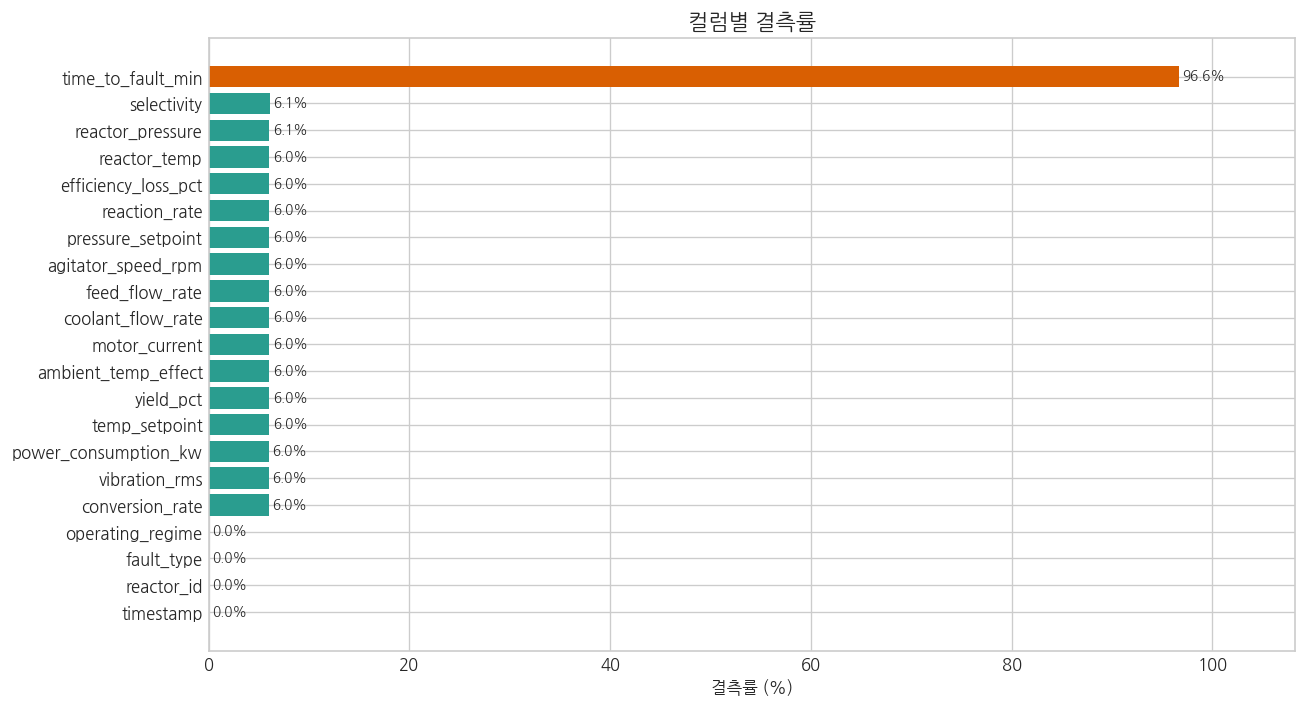

In [3]:
missing = (df.isna().mean() * 100).sort_values(ascending=False).rename("missing_pct")
print(missing.to_frame().to_string())

fig, ax = plt.subplots(figsize=(11, 6))
colors = ["#d95f02" if c == "time_to_fault_min" else "#2a9d8f" for c in missing.index]
ax.barh(missing.index[::-1], missing.values[::-1], color=colors[::-1])
ax.set_title("컬럼별 결측률")
ax.set_xlabel("결측률 (%)")
for y, v in enumerate(missing.values[::-1]):
    ax.text(v + 0.4, y, f"{v:.1f}%", va="center", fontsize=8)
ax.set_xlim(0, max(missing.max() * 1.12, 10))
plt.tight_layout()
plt.show()

ttf_by_fault = df.groupby("fault_type")["time_to_fault_min"].agg(
    rows="size", non_null="count", min="min", median="median", max="max"
)
ttf_by_fault["available_pct"] = ttf_by_fault["non_null"] / ttf_by_fault["rows"] * 100
print("\ntime_to_fault_min의 결함 유형별 가용성")
print(ttf_by_fault.to_string())


**해석 방법**

- 일반 센서의 약 6% 결측은 수집 누락을 모사한 것으로 보입니다. 보간 전에 결측이 연속적으로 발생하는지와 결함 상태에 따라 달라지는지를 추가 확인해야 합니다.
- `time_to_fault_min`은 정상 구간에서 비어 있고 결함 구간에서 결함 종료 방향으로 감소하는 정답성 정보입니다. 결함 분류 입력에 사용하면 데이터 누출이 발생하므로 향후 특징 변수 목록에서 제외해야 합니다.
- `efficiency_loss_pct` 역시 예측 대상이므로 결함 분류 입력으로 쓸지는 실제 서비스 시점에 확보 가능한 정보인지 먼저 판단해야 합니다.


## 3. 운전 조건과 결함 클래스 분포

정상 데이터가 지나치게 많으면 전체 정확도만 높은 모델이 만들어질 수 있습니다. 결함별 관측 수뿐 아니라 서로 이어진 **결함 이벤트 수**도 함께 봅니다.


운전 조건별 행 수
operating_regime
A    388800
B    388800

결함 유형별 행 수와 비율
                         rows    pct
fault_type                          
0 Normal               749699 96.412
1 Cooling degradation    9143  1.176
2 Feed blockage          6842  0.880
3 Sensor drift           4474  0.575
4 Mechanical wear        7442  0.957
<cell-4>:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown

연속 결함 이벤트 요약
                       event_count  min_min  median_min  max_min  total_rows
fault_type                                                                  
1 Cooling degradation           10      308     953.500     1310        9143
2 Feed blockage                  9      202     841.000     1225        6842
3 Sensor drift                   7      266     559.000     1301        4474
4 Mechanical wear                9      325     672.000     1417        7442


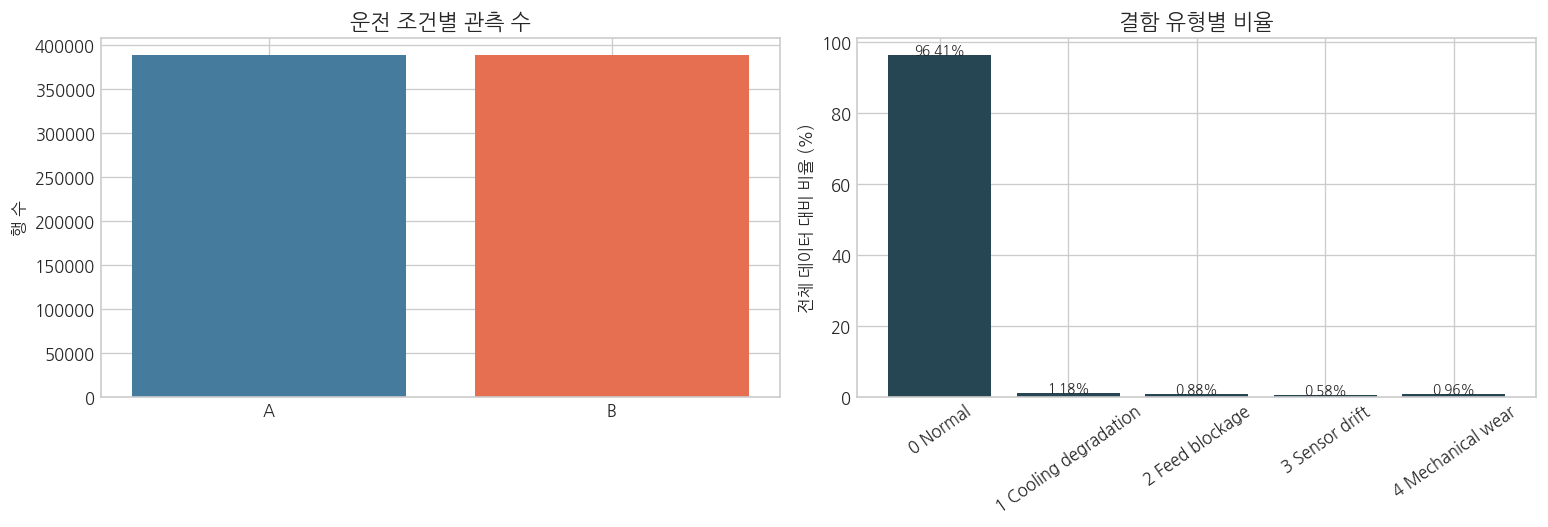

In [4]:
fault_names = {
    0: "0 Normal", 1: "1 Cooling degradation", 2: "2 Feed blockage",
    3: "3 Sensor drift", 4: "4 Mechanical wear",
}

regime_counts = df["operating_regime"].value_counts().sort_index()
fault_counts = df["fault_type"].value_counts().sort_index()
fault_pct = (fault_counts / len(df) * 100).rename("pct")
class_table = pd.concat([fault_counts.rename("rows"), fault_pct], axis=1)
class_table.index = class_table.index.map(fault_names)
print("운전 조건별 행 수")
print(regime_counts.to_string())
print("\n결함 유형별 행 수와 비율")
print(class_table.to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(regime_counts.index, regime_counts.values, color=["#457b9d", "#e76f51"])
axes[0].set_title("운전 조건별 관측 수")
axes[0].set_ylabel("행 수")

axes[1].bar(class_table.index, class_table["pct"], color="#264653")
axes[1].set_title("결함 유형별 비율")
axes[1].set_ylabel("전체 데이터 대비 비율 (%)")
axes[1].tick_params(axis="x", rotation=35)
for i, v in enumerate(class_table["pct"]):
    axes[1].text(i, v + 0.15, f"{v:.2f}%", ha="center", fontsize=8)
plt.tight_layout()
plt.show()

ordered = df.sort_values(["reactor_id", "timestamp"]).copy()
ordered["segment_start"] = ordered.groupby("reactor_id")["fault_type"].transform(lambda s: s.ne(s.shift()))
ordered["segment_id"] = ordered.groupby("reactor_id")["segment_start"].cumsum()
events = (ordered.groupby(["reactor_id", "segment_id"], as_index=False)
          .agg(start=("timestamp", "min"), end=("timestamp", "max"),
               fault_type=("fault_type", "first"), duration_min=("timestamp", "size")))
fault_events = events.query("fault_type != 0").copy()
event_summary = fault_events.groupby("fault_type")["duration_min"].agg(
    event_count="count", min_min="min", median_min="median", max_min="max", total_rows="sum"
)
event_summary.index = event_summary.index.map(fault_names)
print("\n연속 결함 이벤트 요약")
print(event_summary.to_string())


**핵심 포인트**

행 단위 클래스 불균형뿐 아니라 결함 이벤트가 총 35회뿐이라는 점이 중요합니다. 향후 데이터를 무작위 행 단위로 나누면 같은 결함 이벤트의 앞부분과 뒷부분이 학습·평가 데이터에 함께 들어가 성능이 과대평가될 수 있습니다. 시간 또는 이벤트 단위 분할이 필요합니다.


## 4. 주요 변수의 기본 통계와 운전 조건 차이

운전 조건 A와 B는 서로 다른 정상 범위를 가질 수 있습니다. 따라서 정상 상태(`fault_type == 0`)에서 운전 조건별 중앙값과 변동 범위를 먼저 비교합니다. 중앙값과 사분위 범위(IQR)는 극단값에 평균·표준편차보다 덜 민감합니다.


정상 상태의 운전 조건별 요약
operating_regime                  A       B
reactor_temp         median 181.085 194.450
                     mean   181.258 194.576
                     std      1.099   1.104
reactor_pressure     median  15.680  17.557
                     mean    15.679  17.564
                     std      0.108   0.221
feed_flow_rate       median  99.998 108.004
                     mean   100.000 108.004
                     std      0.997   1.201
coolant_flow_rate    median  80.028  72.035
                     mean    80.021  72.021
                     std      1.732   1.853
agitator_speed_rpm   median 299.981 299.982
                     mean   299.995 299.995
                     std      5.005   5.996
vibration_rms        median   1.500   1.500
                     mean     1.500   1.500
                     std      0.050   0.060
motor_current        median  45.999  46.000
                     mean    46.000  46.001
                     std      0.509   0.514
power_consumpti

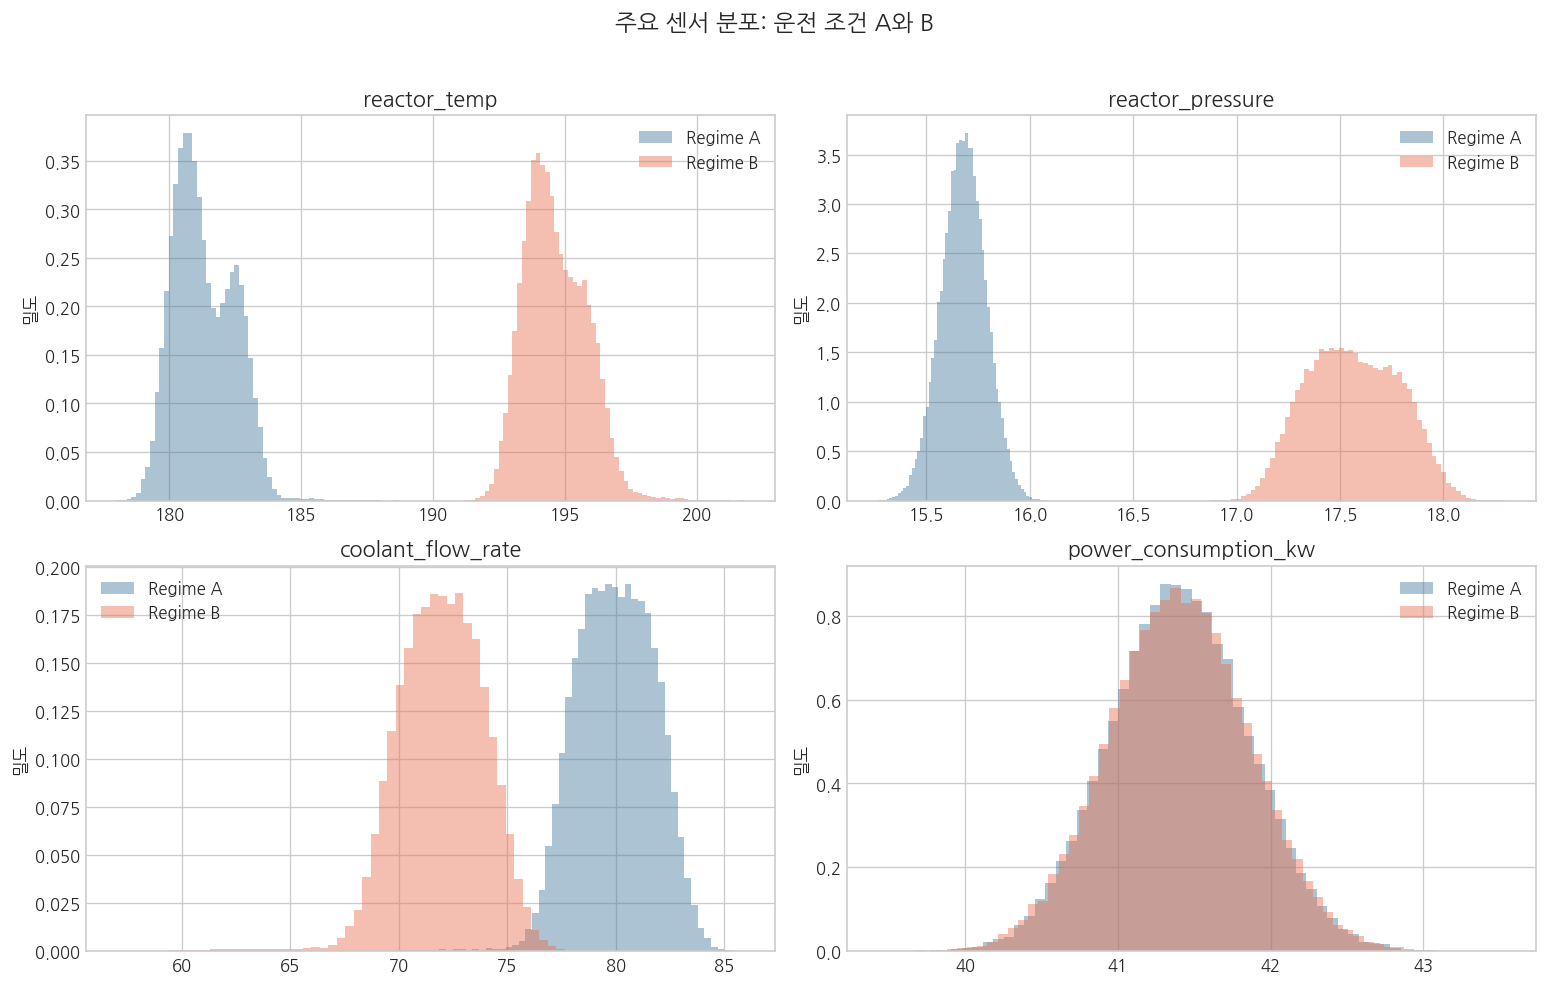

In [5]:
key_cols = [
    "reactor_temp", "reactor_pressure", "feed_flow_rate", "coolant_flow_rate",
    "agitator_speed_rpm", "vibration_rms", "motor_current", "power_consumption_kw",
    "conversion_rate", "yield_pct",
]

normal = df[df["fault_type"].eq(0)]
normal_summary = normal.groupby("operating_regime")[key_cols].agg(["median", "mean", "std"])
print("정상 상태의 운전 조건별 요약")
print(normal_summary.T.to_string())

sample = df.sample(n=min(120_000, len(df)), random_state=42)
plot_cols = ["reactor_temp", "reactor_pressure", "coolant_flow_rate", "power_consumption_kw"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.flat, plot_cols):
    for regime, color in [("A", "#457b9d"), ("B", "#e76f51")]:
        values = sample.loc[sample["operating_regime"].eq(regime), col].dropna()
        ax.hist(values, bins=60, density=True, alpha=0.45, label=f"Regime {regime}", color=color)
    ax.set_title(col)
    ax.set_ylabel("밀도")
    ax.legend()
plt.suptitle("주요 센서 분포: 운전 조건 A와 B", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()


**해석 방법**

두 운전 조건의 분포가 명확히 다르면 하나의 전역 임계값을 사용했을 때 고부하 운전을 이상으로 오인할 수 있습니다. 모델링 단계에서는 운전 조건을 입력 변수로 포함하거나, 반응기·운전 조건별 정상 기준으로 표준화하는 방식을 검토합니다.


## 5. 시간에 따른 전력 사용과 결함 비율

1분 자료를 그대로 그리면 77만 개 선이 겹쳐 흐름을 읽기 어렵습니다. 여기서는 시간 단위로 중앙값을 집계하고, 하루 단위로 다시 요약해 장기 추세를 봅니다. 전력은 순간 출력(kW)이므로 아래 그래프는 사용량(kWh)이 아니라 **전력 수준**의 변화입니다.


<cell-6>:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


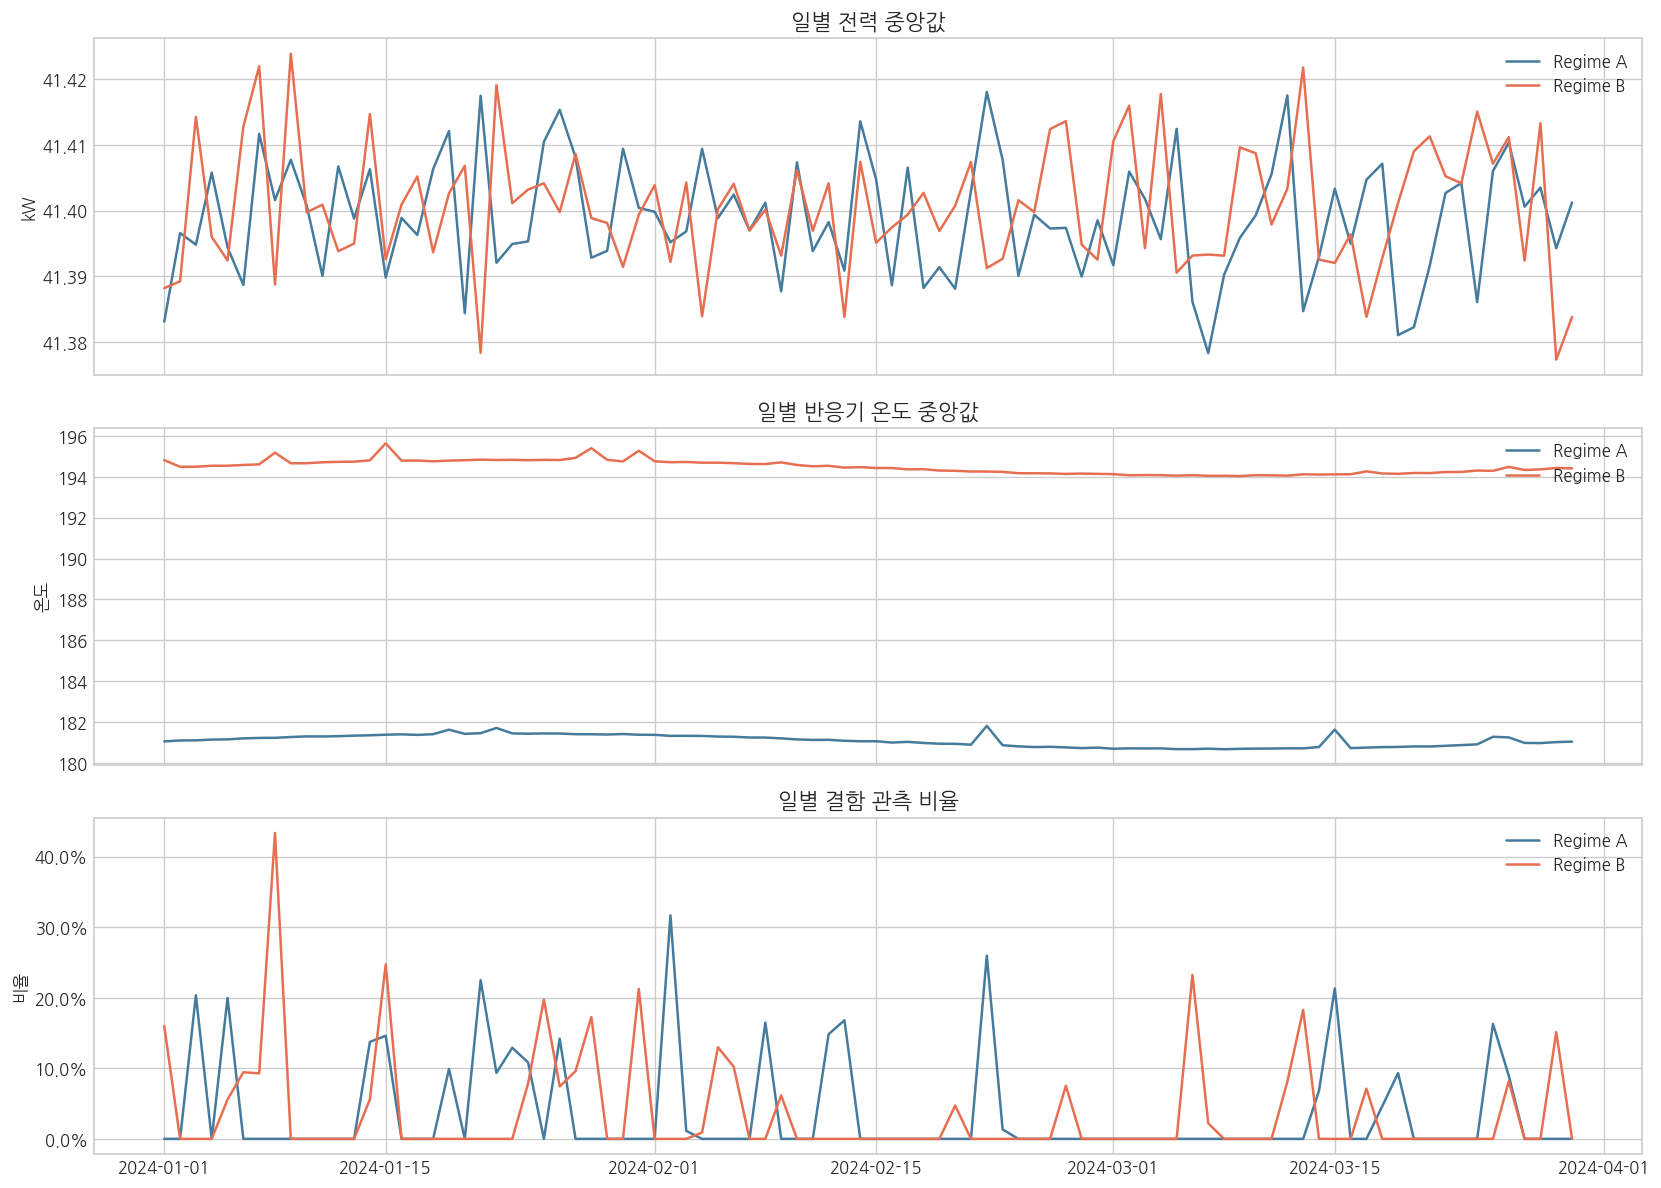

In [6]:
daily = (df.set_index("timestamp")
         .groupby(["operating_regime", pd.Grouper(freq="1D")])
         .agg(power_median=("power_consumption_kw", "median"),
              temp_median=("reactor_temp", "median"),
              fault_rate=("fault_type", lambda s: s.ne(0).mean()))
         .reset_index())

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
for regime, color in [("A", "#457b9d"), ("B", "#e76f51")]:
    g = daily[daily["operating_regime"].eq(regime)]
    axes[0].plot(g["timestamp"], g["power_median"], label=f"Regime {regime}", color=color)
    axes[1].plot(g["timestamp"], g["temp_median"], label=f"Regime {regime}", color=color)
    axes[2].plot(g["timestamp"], g["fault_rate"], label=f"Regime {regime}", color=color)

axes[0].set_title("일별 전력 중앙값")
axes[0].set_ylabel("kW")
axes[1].set_title("일별 반응기 온도 중앙값")
axes[1].set_ylabel("온도")
axes[2].set_title("일별 결함 관측 비율")
axes[2].set_ylabel("비율")
axes[2].yaxis.set_major_formatter(PercentFormatter(1.0))
for ax in axes:
    ax.legend(loc="upper right")
plt.tight_layout()
plt.show()


## 6. 변수 간 상관관계

상관계수는 두 변수가 함께 선형적으로 움직이는 정도를 나타냅니다. 높은 상관은 원인·결과를 뜻하지 않으며, 시계열 추세나 운전 조건 차이만으로도 커질 수 있습니다. 운전 조건의 영향을 줄이기 위해 정상 상태에서 조건별 상관행렬을 따로 봅니다.


<cell-7>:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
정상 상태에서 전력 소비량과의 상관계수
operating_regime          A      B
motor_current         1.000  1.000
power_consumption_kw  1.000  1.000
agitator_speed_rpm    0.196  0.231
reaction_rate        -0.002 -0.001
reactor_temp         -0.002 -0.001
feed_flow_rate        0.002 -0.003
coolant_flow_rate    -0.001  0.001
conversion_rate      -0.001 -0.001
vibration_rms         0.001 -0.002
yield_pct            -0.001 -0.003
reactor_pressure     -0.000  0.000


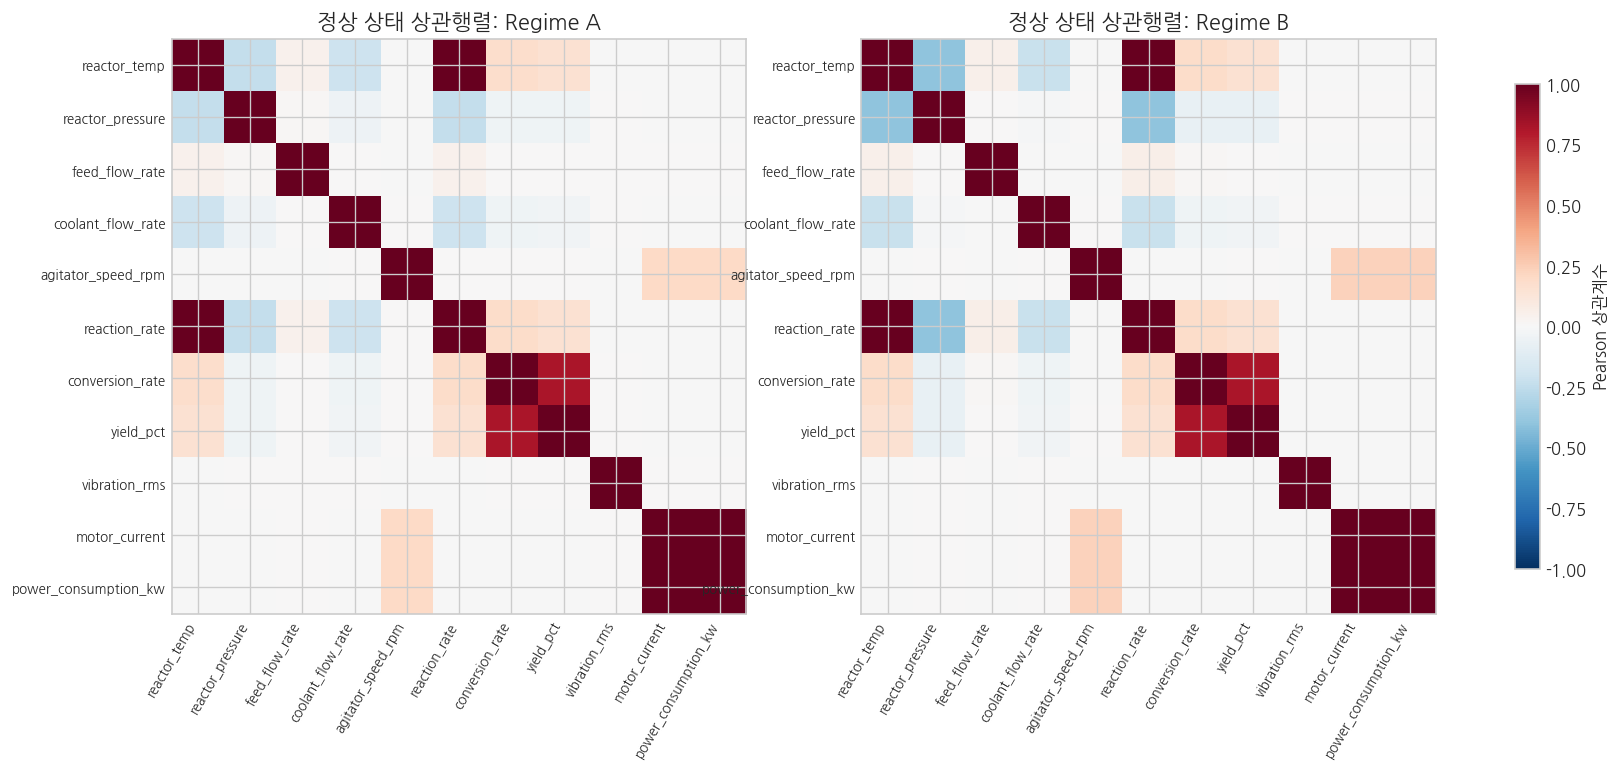

In [7]:
corr_cols = [
    "reactor_temp", "reactor_pressure", "feed_flow_rate", "coolant_flow_rate",
    "agitator_speed_rpm", "reaction_rate", "conversion_rate", "yield_pct",
    "vibration_rms", "motor_current", "power_consumption_kw",
]

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, regime in zip(axes, ["A", "B"]):
    corr = normal.loc[normal["operating_regime"].eq(regime), corr_cols].corr()
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(corr_cols)), corr_cols, fontsize=8)
    ax.set_title(f"정상 상태 상관행렬: Regime {regime}")
fig.colorbar(im, ax=axes, shrink=0.75, label="Pearson 상관계수")
plt.show()

power_corr = normal.groupby("operating_regime")[corr_cols].corr()["power_consumption_kw"].unstack(0)
print("정상 상태에서 전력 소비량과의 상관계수")
print(power_corr.sort_values("A", key=lambda s: s.abs(), ascending=False).to_string())


## 7. 결함 상태에서 나타나는 변수 변화

운전 조건 자체의 차이를 결함 효과로 잘못 해석하지 않도록, 각 조건의 정상 중앙값과 정상 IQR을 기준으로 결함 유형별 중앙값 차이를 계산합니다.

`표준화 차이 = (결함 중앙값 - 같은 운전 조건의 정상 중앙값) / 정상 IQR`

절댓값이 클수록 정상 변동 폭에 비해 변화가 크다는 뜻입니다. 이는 유의성 검정이나 모델 중요도가 아니라 탐색용 효과 크기입니다.


operating_regime  fault_type  reactor_temp  reactor_pressure  feed_flow_rate  coolant_flow_rate  vibration_rms  motor_current  power_consumption_kw  yield_pct           fault_label
               A           1         1.360             0.070           0.010             -1.680         -0.020          0.020                 0.020     -0.020 1 Cooling degradation
               A           2         0.560            -0.070          -7.430             -0.490          0.010         -0.010                -0.010      0.040       2 Feed blockage
               A           3         0.620             0.230           0.060             -0.760          0.060          0.000                 0.010     -0.020        3 Sensor drift
               A           4         0.790            -0.220           0.000             -0.300         14.760          3.630                 0.000      0.100     4 Mechanical wear
               B           1         1.550             0.460          -0.000             -2.240

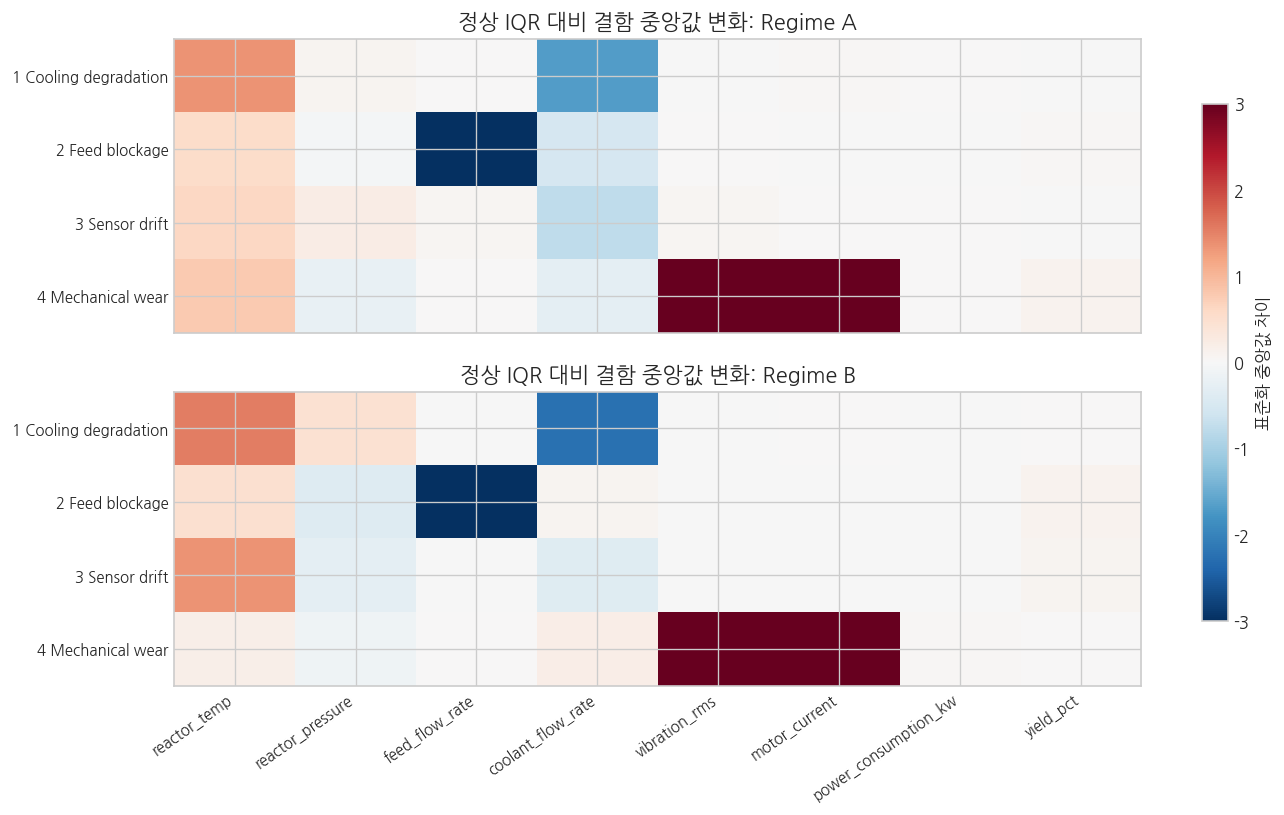

In [8]:
effect_cols = [
    "reactor_temp", "reactor_pressure", "feed_flow_rate", "coolant_flow_rate",
    "vibration_rms", "motor_current", "power_consumption_kw", "yield_pct",
]

baseline = normal.groupby("operating_regime")[effect_cols].agg(
    ["median", lambda s: s.quantile(.75) - s.quantile(.25)]
)
baseline.columns = [f"{c}__{stat}" for c, stat in baseline.columns]

effect_rows = []
for (regime, fault), g in df[df["fault_type"].ne(0)].groupby(["operating_regime", "fault_type"]):
    row = {"operating_regime": regime, "fault_type": fault}
    for col in effect_cols:
        med = baseline.loc[regime, f"{col}__median"]
        iqr = baseline.loc[regime, f"{col}__<lambda_0>"]
        row[col] = (g[col].median() - med) / iqr if iqr and not pd.isna(iqr) else np.nan
    effect_rows.append(row)
effects = pd.DataFrame(effect_rows)
effects["fault_label"] = effects["fault_type"].map(fault_names)
print(effects.round(2).to_string(index=False))

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for ax, regime in zip(axes, ["A", "B"]):
    mat = effects[effects["operating_regime"].eq(regime)].set_index("fault_label")[effect_cols]
    im = ax.imshow(mat, aspect="auto", vmin=-3, vmax=3, cmap="RdBu_r")
    ax.set_yticks(range(len(mat)), mat.index, fontsize=9)
    ax.set_xticks(range(len(effect_cols)), effect_cols, rotation=35, ha="right", fontsize=9)
    ax.set_title(f"정상 IQR 대비 결함 중앙값 변화: Regime {regime}")
fig.colorbar(im, ax=axes, shrink=0.8, label="표준화 중앙값 차이")
plt.show()


## 8. 전력 증가 후보 구간의 탐색

서비스 목표 중 하나인 에너지 사용 증가를 가볍게 탐색합니다. 정상 상태의 반응기별 전력 중앙값과 MAD(Median Absolute Deviation)를 기준으로 `중앙값 + 3 × 1.4826 × MAD`를 초과한 시점을 후보로 표시합니다.

이 기준은 **완성된 이상 탐지 모델이 아닙니다.** 운전 조건과 반응기별 기준선을 나누는 것이 왜 필요한지 확인하고, 결함과의 단순 동시 발생 관계를 보는 용도입니다.


반응기별 정상 전력 기준
            normal_median  normal_mad  high_power_threshold
reactor_id                                                 
A_R1               41.398       0.310                42.779
A_R2               41.399       0.309                42.773
A_R3               41.399       0.309                42.773
B_R1               41.400       0.312                42.790
B_R2               41.401       0.313                42.792
B_R3               41.401       0.313                42.793

운전 조건·결함별 고전력 후보 비율
                             available_power  high_power_candidates  candidate_rate_pct
operating_regime fault_type                                                            
A                0                    352468                    447               0.127
                 1                      4061                      5               0.123
                 2                      3605                      3               0.083
                 3                       937 

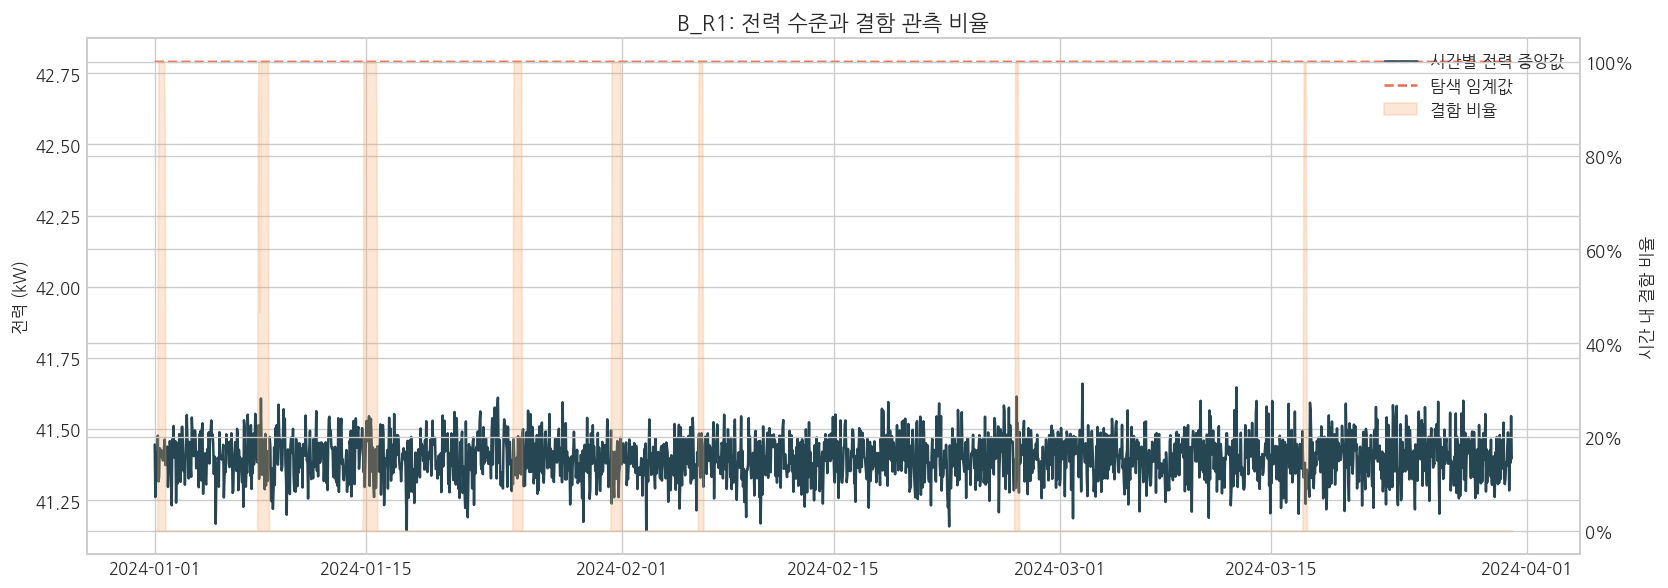

In [9]:
def mad(s):
    med = s.median()
    return (s - med).abs().median()

power_base = (normal.groupby("reactor_id")["power_consumption_kw"]
              .agg(normal_median="median", normal_mad=mad))
power_base["high_power_threshold"] = (
    power_base["normal_median"] + 3 * 1.4826 * power_base["normal_mad"]
)

power_check = df[["timestamp", "reactor_id", "operating_regime", "power_consumption_kw", "fault_type"]].join(
    power_base, on="reactor_id"
)
power_check["high_power_candidate"] = power_check["power_consumption_kw"].gt(
    power_check["high_power_threshold"]
)

candidate_summary = power_check.groupby(["operating_regime", "fault_type"]).agg(
    available_power=("power_consumption_kw", "count"),
    high_power_candidates=("high_power_candidate", "sum"),
)
candidate_summary["candidate_rate_pct"] = (
    candidate_summary["high_power_candidates"] / candidate_summary["available_power"] * 100
)
print("반응기별 정상 전력 기준")
print(power_base.to_string())
print("\n운전 조건·결함별 고전력 후보 비율")
print(candidate_summary.to_string())

example_id = "B_R1"
example = power_check[power_check["reactor_id"].eq(example_id)].set_index("timestamp")
example_hourly = example.resample("1h").agg(
    power=("power_consumption_kw", "median"),
    threshold=("high_power_threshold", "first"),
    fault_rate=("fault_type", lambda s: s.ne(0).mean()),
)
fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.plot(example_hourly.index, example_hourly["power"], color="#264653", label="시간별 전력 중앙값")
ax1.plot(example_hourly.index, example_hourly["threshold"], color="#e76f51", linestyle="--", label="탐색 임계값")
ax1.set_ylabel("전력 (kW)")
ax1.set_title(f"{example_id}: 전력 수준과 결함 관측 비율")
ax2 = ax1.twinx()
ax2.fill_between(example_hourly.index, 0, example_hourly["fault_rate"], color="#f4a261", alpha=.25, label="결함 비율")
ax2.set_ylabel("시간 내 결함 비율")
ax2.yaxis.set_major_formatter(PercentFormatter(1.0))
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")
plt.tight_layout()
plt.show()


## 9. EDA 결론과 다음 단계

이번 분석에서 확인한 내용은 다음과 같습니다.

- 실제 CSV는 **777,600행, 21열**이며 6개 반응기에 대해 2024-01-01부터 2024-03-30까지 1분 간격으로 연속 기록되어 있습니다.
- `(reactor_id, timestamp)` 중복과 1분 간격의 시간 누락은 없습니다.
- 일반 센서 결측률은 대체로 약 6%입니다. 결측 처리 시 모든 컬럼을 한꺼번에 보간하기보다 반응기별·연속 결측 길이별로 방법을 정해야 합니다.
- 정상 클래스가 대부분이며 결함은 35개 연속 이벤트로 구성됩니다. 행 단위 무작위 분할은 정보 누출 위험이 큽니다.
- 운전 조건 A/B의 정상 분포가 다르므로 조건별 기준 또는 조건을 반영한 모델이 필요합니다.
- `fault_type`, `time_to_fault_min`, `efficiency_loss_pct`는 예측 대상 또는 정답성 정보입니다. 특히 `time_to_fault_min`은 결함 분류 입력에서 제외해야 합니다.
- 전력 증가 후보 기준은 EDA용 기준선일 뿐입니다. 다음 단계에서 지속 시간, 결측 처리, 운전 조건, 결함 이벤트 시작 전 선행 신호를 함께 고려해야 합니다.

### 모델링 전에 권장하는 다음 분석

1. 반응기별 결측 연속 길이와 결측 발생 메커니즘 확인
2. 결함 이벤트 시작 전 6~24시간의 센서 변화량과 이동 통계 탐색
3. 시간·이벤트 단위 학습/검증/테스트 분할 설계
4. 서비스에서 실제로 사용할 수 있는 입력 변수 목록 확정

이 노트북은 원본 CSV를 변경하지 않습니다.
